In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import tensorflow as tf


In [2]:
relu= tf.keras.activations.relu
print(relu(-5))
print(relu(0))
print(relu(9))

tf.Tensor(0, shape=(), dtype=int32)
tf.Tensor(0, shape=(), dtype=int32)
tf.Tensor(9, shape=(), dtype=int32)


In [3]:
sigmoid= tf.keras.activations.sigmoid
print(sigmoid(-5.0))
print(sigmoid(0.0))
print(sigmoid(9.0))

tf.Tensor(0.006692851, shape=(), dtype=float32)
tf.Tensor(0.5, shape=(), dtype=float32)
tf.Tensor(0.9998766, shape=(), dtype=float32)


In [4]:
tanh= tf.keras.activations.tanh
print(tanh(-5.0))
print(tanh(0.0))
print(tanh(9.0))

tf.Tensor(-0.99990916, shape=(), dtype=float32)
tf.Tensor(0.0, shape=(), dtype=float32)
tf.Tensor(1.0, shape=(), dtype=float32)


In [5]:
train_path='/content/drive/MyDrive/Chest_Xray/train'
test_path='/content/drive/MyDrive/Chest_Xray/test'
print(train_path)
print(test_path)

/content/drive/MyDrive/Chest_Xray/train
/content/drive/MyDrive/Chest_Xray/test


In [6]:
print(os.listdir(train_path))
print(os.listdir(test_path))

['normal', 'penumonia']
['penumonia', 'normal']


In [7]:
normal_path=os.path.join(train_path,'normal')
pneumonia_path=os.path.join(train_path,'penumonia')
print(len(os.listdir(normal_path)))
print(len(os.listdir(pneumonia_path)))

297
304


In [8]:
normal_path_test=os.path.join(test_path,'normal')
pneumonia_path_test=os.path.join(test_path,'penumonia')
print(len(os.listdir(normal_path_test)))
print(len(os.listdir(pneumonia_path_test)))


136
162


In [9]:
train_data=tf.keras.preprocessing.image_dataset_from_directory(train_path,image_size=(128,128),batch_size=32)

print(train_data)
display(train_data.class_names)

Found 601 files belonging to 2 classes.
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


['normal', 'penumonia']

In [10]:
for images,labels in train_data.take(1):
  print("img shape",images.shape)
  print("label shape",labels.shape)
  print("labels",labels.shape)


img shape (32, 128, 128, 3)
label shape (32,)
labels (32,)


In [11]:
for images,labels in train_data.take(2):
  first_img=images[0]
  first_label=labels[0]
  print(first_img.shape)



(128, 128, 3)
(128, 128, 3)


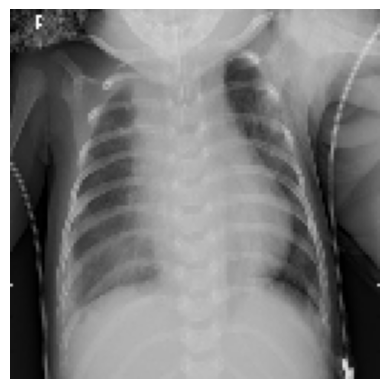

In [12]:
import matplotlib.pyplot as plt

for images,labels in train_data.take(1):

  plt.imshow(images[0].numpy().astype("uint8"))
  plt.axis("off")
  plt.show()



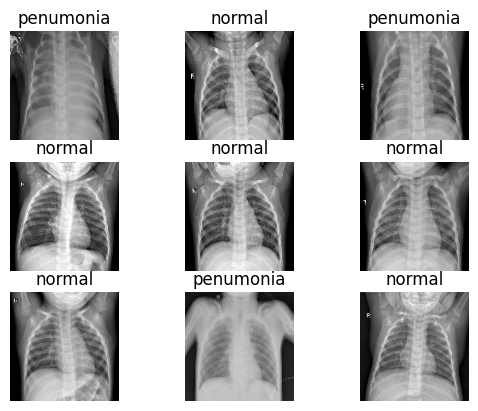

In [13]:
import matplotlib.pyplot as plt

for images,labels in train_data.take(1):
  for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(train_data.class_names[labels[i]])
    plt.axis("off")

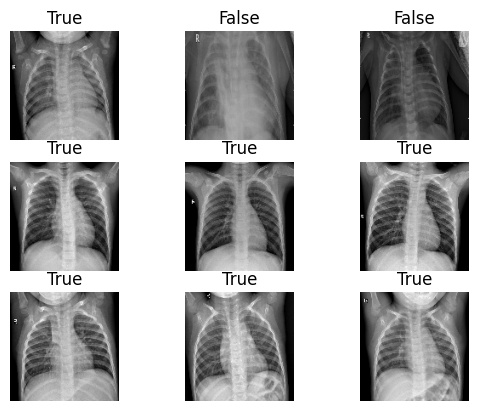

In [14]:
import matplotlib.pyplot as plt

for images,labels in train_data.take(1):
  for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(train_data.class_names[labels[i]]=="normal")
    plt.axis("off")
#

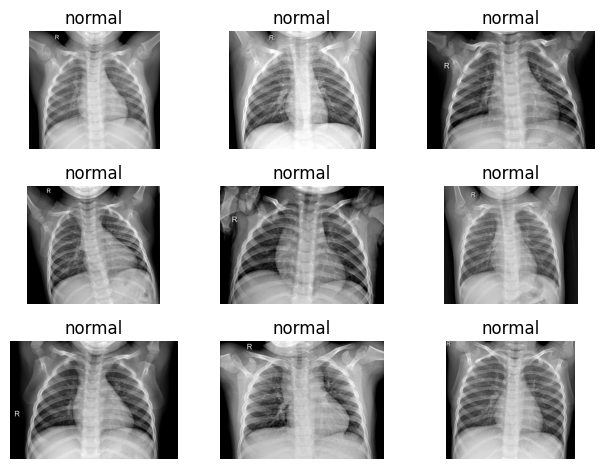

In [15]:
import os
import matplotlib.pyplot as plt
from PIL import Image


normal_images = os.listdir(normal_path)


for i in range(min(9, len(normal_images))):
    img_name = normal_images[i]
    img_filepath = os.path.join(normal_path, img_name)
    img = Image.open(img_filepath)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title("normal")
    plt.axis("off")

plt.tight_layout()
plt.show()

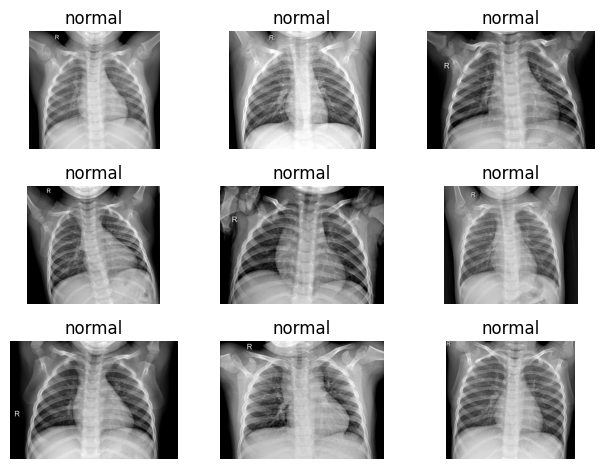

In [16]:
import os
import matplotlib.pyplot as plt
from PIL import Image

normal_images = os.listdir(normal_path)


# Loop through the first 9 images using enumerate
for i, img_name in enumerate(normal_images[:9]):
    img_filepath = os.path.join(normal_path, img_name)
    img = Image.open(img_filepath)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title("normal")
    plt.axis("off")

plt.tight_layout()
plt.show()

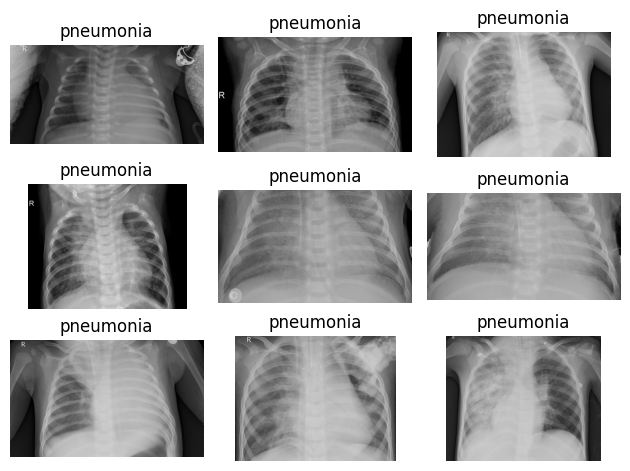

In [17]:
import os
import matplotlib.pyplot as plt
from PIL import Image

pneumonia_images = os.listdir(pneumonia_path)



for i, img_name in enumerate(pneumonia_images[:9]):
    img_filepath = os.path.join(pneumonia_path, img_name)
    img = Image.open(img_filepath)
    plt.subplot(3, 3, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title("pneumonia")
    plt.axis("off")

plt.tight_layout()
plt.show()



In [18]:
model=tf.keras.models.Sequential([
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(32,3,activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64,3,activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128,activation="relu"),
    tf.keras.layers.Dense(1,activation='sigmoid')
])




In [19]:
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [20]:
from sklearn.metrics import accuracy_score,classification_report

model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics=['accuracy']
)



In [21]:
history=model.fit(train_data,epochs=10)

Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 17s 449ms/step - accuracy: 0.6606 - loss: 0.8440
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 300ms/step - accuracy: 0.8619 - loss: 0.3118
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 342ms/step - accuracy: 0.9468 - loss: 0.1519
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 249ms/step - accuracy: 0.9651 - loss: 0.0753
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 245ms/step - accuracy: 0.9884 - loss: 0.0460
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 367ms/step - accuracy: 0.9950 - loss: 0.0280
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 242ms/step - accuracy: 0.9933 - loss: 0.0195
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 374ms/step - accuracy: 0.9967 - loss: 0.0098
Epoch 9/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 251ms/step - accuracy: 1.0000 - loss: 0.0050
Epoch 10/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 327ms/step - accuracy: 1.0000 - loss: 0.0029


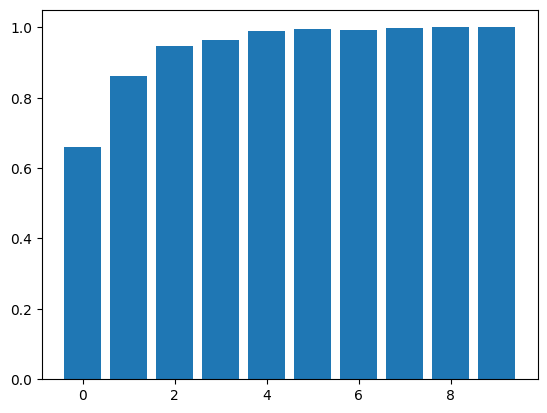

In [22]:
plt.bar(history.epoch,history.history['accuracy'])
plt.show()

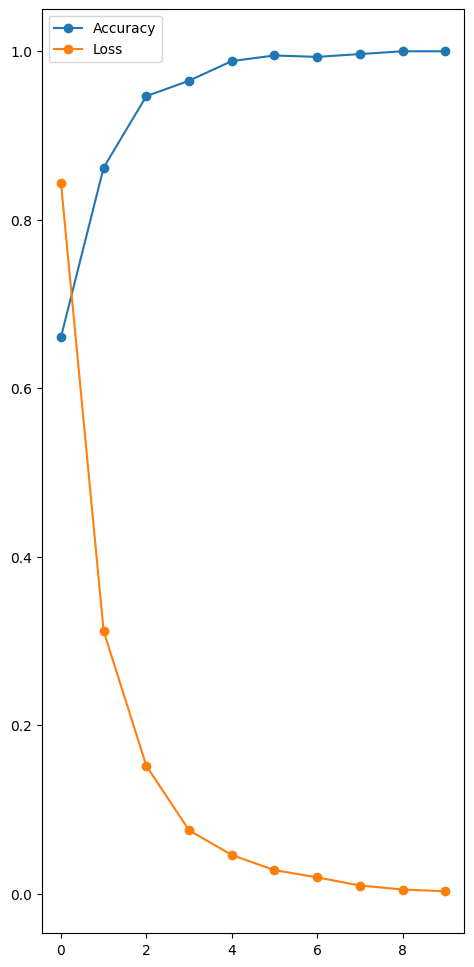

In [23]:
plt.figure(figsize=(12,12))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],marker='o',label="Accuracy")
plt.plot(history.history['loss'],marker='o',label="Loss")
plt.legend()
plt.show()

In [24]:
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,177,349 (84.60 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 14,784,900 (56.40 MB)

None


In [25]:
test_data= tf.keras.utils.image_dataset_from_directory(test_path,image_size=(128,128),batch_size=32)
print(test_data)


Found 298 files belonging to 2 classes.
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [26]:
test_loss,test_accuracy= model.evaluate(test_data)
print(f"Test Loss:{test_loss}")
print(f"Test Accuracy:{test_accuracy}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - accuracy: 0.8188 - loss: 0.7324
Test Loss:0.7324487566947937
Test Accuracy:0.818791925907135


In [27]:
predict=model.predict(test_data)
print(predict[:5])

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 259ms/step
[[6.9658458e-01]
 [9.9995244e-01]
 [9.9999464e-01]
 [9.9936038e-01]
 [1.3169235e-07]]


In [28]:
predicted_label=(predict>=0.5).astype(int).flatten()
print(predicted_label[:5])

[1 1 1 1 0]


In [29]:
import tensorflow as tf
import numpy as np
actual_labels= np.concatenate([
    labels.numpy()
    for images,labels in test_data

])
print(actual_labels[:5])

[0 1 1 0 1]


In [30]:
from sklearn.metrics import classification_report, confusion_matrix

# Print classification metrics to compare actual vs predicted
print("Classification Report:")
print(classification_report(actual_labels, predicted_label))

print("Confusion Matrix:")
display(confusion_matrix(actual_labels, predicted_label))

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.38      0.42       136
           1       0.55      0.65      0.60       162

    accuracy                           0.52       298
   macro avg       0.51      0.51      0.51       298
weighted avg       0.52      0.52      0.52       298

Confusion Matrix:


array([[ 51,  85],
       [ 57, 105]])

<Axes: >

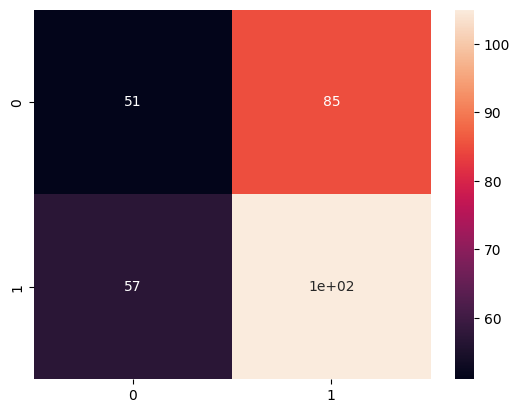

In [31]:
sns.heatmap(confusion_matrix(actual_labels, predicted_label),annot=True)


In [32]:
model.save('chest_xray_ngrok.h5')

In [33]:
!pip install fastapi uvicorn pyngrok python-multipart jinja2 tensorflow pillow -q

In [58]:
%%writefile /content/chest_xray_ngrok/app.py


from fastapi import FastAPI, Request, UploadFile, File
from fastapi.responses import HTMLResponse
from fastapi.templating import Jinja2Templates


import tensorflow as tf
from PIL import Image
import numpy as np
import io


# =========================================================
# FASTAPI APP
# =========================================================


app = FastAPI()


# =========================================================
# HTML TEMPLATE LOCATION
# =========================================================


templates = Jinja2Templates(
    directory="/content/chest_xray_ngrok/templates"
)


# =========================================================
# LOAD TRAINED CNN MODEL
# =========================================================


model = tf.keras.models.load_model(
    "/content/chest_xray_ngrok/chest_xray_ngrok.h5"
)


print("CNN model loaded successfully!")


# =========================================================
# HOME PAGE
# =========================================================


@app.get("/", response_class=HTMLResponse)
async def home(request: Request):


    return templates.TemplateResponse(
        request=request,
        name="index.html",
        context={
            "request": request,
            "prediction": None,
            "confidence": 0,
            "is_pneumonia": False,
            "is_normal": False
        }
    )


# =========================================================
# PREDICTION
# =========================================================


@app.post("/predict", response_class=HTMLResponse)
async def predict(
    request: Request,
    file: UploadFile = File(...)
):


    # -----------------------------------------------------
    # Uploaded image read karo
    # -----------------------------------------------------


    image_data = await file.read()


    # -----------------------------------------------------
    # Image open karo
    # -----------------------------------------------------


    img = Image.open(
        io.BytesIO(image_data)
    ).convert("RGB")


    # -----------------------------------------------------
    # Image resize
    # Training ke waqt 128 x 128 use hua tha
    # -----------------------------------------------------


    img = img.resize((128, 128))


    # -----------------------------------------------------
    # NumPy array
    # -----------------------------------------------------


    img_array = np.array(
        img
    ).astype("float32")


    # -----------------------------------------------------
    # Batch dimension
    # Shape:
    # (128,128,3)
    #        ↓
    # (1,128,128,3)
    # -----------------------------------------------------


    img_array = np.expand_dims(
        img_array,
        axis=0
    )


    # -----------------------------------------------------
    # CNN prediction
    # -----------------------------------------------------


    score = float(
        model.predict(
            img_array,
            verbose=0
        )[0][0]
    )


    # -----------------------------------------------------
    # Prediction decide karo
    # -----------------------------------------------------


    if score >= 0.5:


        prediction = "PNEUMONIA"


        confidence = score * 100


        is_pneumonia = True
        is_normal = False


    else:


        prediction = "NORMAL"


        confidence = (1 - score) * 100


        is_pneumonia = False
        is_normal = True


    # -----------------------------------------------------
    # Confidence round
    # -----------------------------------------------------


    confidence = round(
        confidence,
        2
    )


    # -----------------------------------------------------
    # Result HTML ko return karo
    # -----------------------------------------------------


    return templates.TemplateResponse(
        request=request,
        name="index.html",
        context={
            "request": request,
            "prediction": prediction,
            "confidence": confidence,
            "is_pneumonia": is_pneumonia,
            "is_normal": is_normal
        }
    )



Overwriting /content/chest_xray_ngrok/app.py


In [59]:
!pkill -9 -f uvicorn || true

^C


In [60]:
%cd /content/chest_xray_ngrok
!rm -f fastapi.log
!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > fastapi.log 2>&1 &

/content/chest_xray_ngrok


In [61]:
import time
time.sleep(5)
!tail -30 fastapi.log

W0000 00:00:1791563809.388512   13248 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [13248]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


In [62]:
import requests
response = requests.get('http://127.0.0.1:8000/')
print(response.status_code)

200


In [63]:
from pyngrok import ngrok

NGROK_TOKEN = "3KMH35P8D43TNxCzTaINxzuConb_73munRbaLNuapEuc9grGs"
ngrok.set_auth_token(NGROK_TOKEN)
print("Ngrok authtoken has been set successfully!")

Ngrok authtoken has been set successfully!


In [64]:

public_url = ngrok.connect(8000, "http")
print("Public URL for your FastAPI application:", public_url)

Public URL for your FastAPI application: NgrokTunnel: "https://gap-unmixable-pointy.ngrok-free.dev" -> "http://localhost:8000"


In [ ]:
#!pip install gradio -q

In [ ]:
# import gradio as gr
# import tensorflow as tf
# import numpy as np
# from PIL import Image

# # 1. Load the trained model
# model_path = '/content/chest_xray_ngrok.h5'
# model = tf.keras.models.load_model(model_path)

# # 2. Define the prediction function
# def predict_chest_xray(img):
#     if img is None:
#         return "Please upload an image."

#     # Convert Gradio input (which is a NumPy array or PIL image) to PIL for resizing
#     if not isinstance(img, Image.Image):
#         img = Image.fromarray(img)

#     # Preprocess image: resize to 128x128 and convert to float32
#     img = img.convert('RGB')
#     img = img.resize((128, 128))
#     img_array = np.array(img).astype('float32')

#     # Add batch dimension: (1, 128, 128, 3)
#     img_array = np.expand_dims(img_array, axis=0)

#     # Get model prediction score
#     score = float(model.predict(img_array, verbose=0)[0][0])

#     # Determine prediction outcome and confidence
#     if score >= 0.5:
#         prediction = "PNEUMONIA"
#         confidence = score
#     else:
#         prediction = "NORMAL"
#         confidence = 1.0 - score

#     return {"NORMAL": 1.0 - score, "PNEUMONIA": score}

# # 3. Design and launch the Gradio Interface
# demo = gr.Interface(
#     fn=predict_chest_xray,
#     inputs=gr.Image(type="pil", label="Upload Chest X-ray Image"),
#     outputs=gr.Label(num_top_classes=2, label="Model Decision"),
#     title="Chest X-Ray Pneumonia Classifier",
#     description="Upload a chest X-ray image to check if it indicates Normal conditions or Pneumonia.",
#     examples=[
#         # You can add example image paths here if desired
#     ]
# )

# # Set share=True to get a public URL from Gradio
# demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3e3490dcaab8e56477.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
